
# FMCE-Style FMCS Dataset Construction (Clean Config Version)

This notebook does the following for **BERT on Yahoo! Answers Topics**:

1. Train a small BERT from scratch and save a checkpoint **after every epoch**.
2. Record epoch-wise training / validation loss and accuracy.
3. Compute **CQI** and determine the **convergence interval** following the
   *Feature Map Convergence Evaluation for Functional Module* paper.
4. Split the convergence interval into **K phases** in log-loss space
   and pick a representative epoch for each phase.
5. For each phase, extract hidden states from a chosen BERT layer, pool them,
   and build an FMCS dataset `(fmcs_features.npy, fmcs_labels.npy)`.

All important hyperparameters live in a single `Config` dataclass
so they are not duplicated across the notebook.


In [1]:

#@title 🔐 Mount Google Drive (optional)
try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
    print("✅ Google Drive mounted.")
except Exception as e:
    print("⚠️ Not running in Colab or Drive unavailable, skipping mount.")


Mounted at /content/drive
✅ Google Drive mounted.


In [2]:

#@title 📦 Install dependencies
import sys, subprocess

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-U"] + ([pkg] if isinstance(pkg, str) else pkg), check=False)

pkgs = [
    "transformers>=4.44.0",
    "datasets>=2.19.0",
    "accelerate>=0.34.0",
    "evaluate>=0.4.1",
    "scipy",
    "matplotlib"
]
print("Installing:", pkgs)
pip_install(pkgs)
print("✅ Dependency installation finished (ignore harmless warnings).")


Installing: ['transformers>=4.44.0', 'datasets>=2.19.0', 'accelerate>=0.34.0', 'evaluate>=0.4.1', 'scipy', 'matplotlib']
✅ Dependency installation finished (ignore harmless warnings).


In [29]:

#@title ⚙️ Global Config (single source of truth)

import os, torch
from dataclasses import dataclass

@dataclass
class Config:
    # ------------ Data & Task ------------
    dataset_name: str = "yahoo_answers_topics"
    num_labels: int = 10

    # ------------ Model (mini-BERT) ------------
    base_model_name: str = "bert-base-uncased"
    num_hidden_layers: int = 3
    hidden_size: int = 256
    intermediate_size: int = 1024
    num_attention_heads: int = 4
    max_position_embeddings: int = 256

    # ------------ Training ------------
    train_epochs: int = 25
    max_length: int = 128
    train_batch_size: int = 256
    eval_batch_size: int = 256
    lr: float = 1e-4

    # ------------ FMCE / CQI ------------
    K_phases: int = 4          # desired number of FMCS phases
    cqi_window: int = 3         # window size for CQI moving average
    cqi_threshold: float = 1e-4 # CQI convergence threshold μ

    # ------------ Feature Extraction ------------
    target_layer: int = -1        # which BERT encoder layer to use (-1 = last)
    feature_pooling: str = "mean" # "mean" or "cls"
    extract_subset: int | None = None  # use None for all training samples

    # ------------ Paths ------------
    base_dir: str = "/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25"
    ckpt_root: str = "/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25"
    fmcs_dir: str = "/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_yahoo_25"

    # ------------ Device ------------
    device: str = "cuda" if torch.cuda.is_available() else "cpu"


CFG = Config()

os.makedirs(CFG.base_dir, exist_ok=True)
os.makedirs(CFG.ckpt_root, exist_ok=True)
os.makedirs(CFG.fmcs_dir, exist_ok=True)

print(CFG)


Config(dataset_name='yahoo_answers_topics', num_labels=10, base_model_name='bert-base-uncased', num_hidden_layers=3, hidden_size=256, intermediate_size=1024, num_attention_heads=4, max_position_embeddings=256, train_epochs=25, max_length=128, train_batch_size=256, eval_batch_size=256, lr=0.0001, K_phases=4, cqi_window=3, cqi_threshold=0.0001, target_layer=-1, feature_pooling='mean', extract_subset=None, base_dir='/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25', ckpt_root='/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25', fmcs_dir='/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_yahoo_25', device='cuda')


In [4]:

#@title 📚 Load Yahoo! Answers Topics & prepare splits

from datasets import load_dataset, ClassLabel

raw = load_dataset(CFG.dataset_name)
train_raw = raw["train"]
test_raw = raw["test"]
print("Raw train size:", len(train_raw))
print("Raw test  size:", len(test_raw))

# 9:1 split of train_raw into train/val (stratified by topic)
split = train_raw.train_test_split(test_size=0.1, seed=42, stratify_by_column="topic")
train_ds = split["train"]
val_ds   = split["test"]

def merge_text(example):
    title = example.get("question_title", "") or ""
    content = example.get("question_content", "") or ""
    answer = example.get("best_answer", "") or ""
    example["text"] = " ".join([title, content, answer]).strip()
    example["label"] = int(example["topic"])
    return example

train_ds = train_ds.map(merge_text, remove_columns=["id", "question_title", "question_content", "best_answer", "topic"])
val_ds   = val_ds.map(merge_text,   remove_columns=["id", "question_title", "question_content", "best_answer", "topic"])

print("Prepared train size:", len(train_ds))
print("Prepared  val size:", len(val_ds))
print("Example text:", train_ds[0]["text"][:200], "...")
print("Example label:", train_ds[0]["label"])


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

yahoo_answers_topics/train-00000-of-0000(…):   0%|          | 0.00/241M [00:00<?, ?B/s]

yahoo_answers_topics/train-00001-of-0000(…):   0%|          | 0.00/270M [00:00<?, ?B/s]

yahoo_answers_topics/test-00000-of-00001(…):   0%|          | 0.00/21.9M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Raw train size: 1400000
Raw test  size: 60000


Map:   0%|          | 0/1260000 [00:00<?, ? examples/s]

Map:   0%|          | 0/140000 [00:00<?, ? examples/s]

Prepared train size: 1260000
Prepared  val size: 140000
Example text: How do European people dress?  Nowadays the usualy wear clothes. ...
Example label: 0


In [5]:

#@title ✂️ Tokenize & build DataLoaders

from transformers import AutoTokenizer, DataCollatorWithPadding
from torch.utils.data import DataLoader

tokenizer = AutoTokenizer.from_pretrained(CFG.base_model_name)

def tokenize_fn(batch):
    return tokenizer(
        batch["text"],
        padding=False,
        truncation=True,
        max_length=CFG.max_length,
    )

train_enc = train_ds.map(tokenize_fn, batched=True)
val_enc   = val_ds.map(tokenize_fn,   batched=True)

cols_to_keep = ["input_ids", "attention_mask", "label"]
train_enc.set_format(type="torch", columns=cols_to_keep)
val_enc.set_format(type="torch", columns=cols_to_keep)

# Subset for feature extraction if desired
if CFG.extract_subset is not None and CFG.extract_subset < len(train_enc):
    train_extract = train_enc.select(range(CFG.extract_subset))
else:
    train_extract = train_enc

print("Tokenized train size:", len(train_enc))
print("Tokenized  val size:", len(val_enc))
print("Train_extract size (for FMCS):", len(train_extract))

data_collator = DataCollatorWithPadding(tokenizer)

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_enc,
    batch_size=CFG.train_batch_size,
    shuffle=True,
    collate_fn=data_collator,
)

val_loader = DataLoader(
    val_enc,
    batch_size=CFG.eval_batch_size,
    shuffle=False,
    collate_fn=data_collator,
)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1260000 [00:00<?, ? examples/s]

Map:   0%|          | 0/140000 [00:00<?, ? examples/s]

Tokenized train size: 1260000
Tokenized  val size: 140000
Train_extract size (for FMCS): 1260000


In [6]:

#@title 🧠 Build mini-BERT model

from transformers import BertConfig, BertForSequenceClassification

mini_cfg = BertConfig(
    vocab_size=tokenizer.vocab_size,
    num_hidden_layers=CFG.num_hidden_layers,
    hidden_size=CFG.hidden_size,
    intermediate_size=CFG.intermediate_size,
    num_attention_heads=CFG.num_attention_heads,
    max_position_embeddings=CFG.max_position_embeddings,
    num_labels=CFG.num_labels,
    hidden_dropout_prob=0.2,
    attention_probs_dropout_prob=0.2,
)

model = BertForSequenceClassification(mini_cfg).to(CFG.device)
print(
    f"Initialized mini-BERT with {mini_cfg.num_hidden_layers} layers, "
    f"hidden={mini_cfg.hidden_size}, device={CFG.device}"
)


Initialized mini-BERT with 3 layers, hidden=256, device=cuda


In [7]:
#@title 🚂 Train BERT & save per-epoch checkpoints

import torch
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import json, numpy as np
import os, time

optimizer = AdamW(model.parameters(), lr=CFG.lr)
scheduler = CosineAnnealingLR(optimizer, T_max=CFG.train_epochs)

epoch_logs = {
    "train_loss": [],
    "val_loss":   [],
    "train_acc":  [],
    "val_acc":    [],
    "epoch_time": [],
}

def format_seconds(t):
    """把秒格式化成 xx min xx sec 形式"""
    if t < 60:
        return f"{t:.1f} sec"
    else:
        mins = int(t // 60)
        secs = t % 60
        return f"{mins} min {secs:.1f} sec"

def run_epoch(loader, train: bool):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch in loader:
        label_key = "labels" if "labels" in batch else "label"
        labels = batch[label_key].to(CFG.device)

        batch_inputs = {
            k: v.to(CFG.device) for k, v in batch.items() if k != label_key
        }

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            outputs = model(**batch_inputs, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / max(total, 1)
    acc = correct / max(total, 1)
    return avg_loss, acc


# -------------------------
# 🕒 添加总计时
# -------------------------
train_start = time.time()

for epoch in range(1, CFG.train_epochs + 1):
    print(f"===== Epoch {epoch}/{CFG.train_epochs} =====")

    epoch_start = time.time()

    # ---- 训练和验证 ----
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss,   val_acc   = run_epoch(val_loader,   train=False)

    scheduler.step()

    # ---- 记录日志 ----
    epoch_logs["train_loss"].append(float(train_loss))
    epoch_logs["val_loss"].append(float(val_loss))
    epoch_logs["train_acc"].append(float(train_acc))
    epoch_logs["val_acc"].append(float(val_acc))

    epoch_time = time.time() - epoch_start
    epoch_logs["epoch_time"].append(epoch_time)

    print(
        f"Train: loss={train_loss:.4f}, acc={train_acc:.4f} | "
        f"Val: loss={val_loss:.4f}, acc={val_acc:.4f}"
    )
    print(f"⏱ Epoch time: {format_seconds(epoch_time)}")

    # ---- 保存参数 ----
    ckpt_dir = os.path.join(CFG.ckpt_root, f"epoch_{epoch}")
    os.makedirs(ckpt_dir, exist_ok=True)
    model.save_pretrained(ckpt_dir)
    tokenizer.save_pretrained(ckpt_dir)
    print("💾 Saved checkpoint to:", ckpt_dir)

# -------------------------
# 🕒 最终总时间
# -------------------------
total_time = time.time() - train_start
print(f"\n===============================")
print(f"🔥 TOTAL TRAINING TIME: {format_seconds(total_time)}")
print(f"===============================\n")

# 保存日志
logs_path = os.path.join(CFG.ckpt_root, "epoch_logs.json")
with open(logs_path, "w") as f:
    json.dump(epoch_logs, f, indent=2)
print("✅ Saved epoch logs to:", logs_path)


===== Epoch 1/25 =====
Train: loss=0.9955, acc=0.6800 | Val: loss=0.8549, acc=0.7245
⏱ Epoch time: 7 min 29.3 sec
💾 Saved checkpoint to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_1
===== Epoch 2/25 =====
Train: loss=0.8221, acc=0.7348 | Val: loss=0.8306, acc=0.7315
⏱ Epoch time: 7 min 29.0 sec
💾 Saved checkpoint to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_2
===== Epoch 3/25 =====
Train: loss=0.7847, acc=0.7452 | Val: loss=0.8233, acc=0.7340
⏱ Epoch time: 7 min 29.4 sec
💾 Saved checkpoint to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_3
===== Epoch 4/25 =====
Train: loss=0.7578, acc=0.7526 | Val: loss=0.8307, acc=0.7341
⏱ Epoch time: 7 min 28.8 sec
💾 Saved checkpoint to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_4
===== Epoch 5/25 =====
Train: loss=0.7345, acc=0.7598 | Val: loss=0.8320, acc=0.7342
⏱ Epoch time: 7 min 28.6 sec
💾 Saved checkpoint to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ck

Val loss   : [0.854881   0.8305863  0.82334289 0.83070941 0.83200434 0.84674749
 0.85284809 0.87234079 0.89533445 0.92038215 0.93469881 0.95984078
 0.97776946 1.00683348 1.02534361 1.04871594 1.07435877 1.09600404
 1.10415013 1.12447979 1.13339796 1.14171701 1.14959473 1.14952262
 1.15176807]
Smoothed   : [0.84678277 0.83627006 0.82821287 0.82868555 0.83648708 0.84386664
 0.85731212 0.87350778 0.89601913 0.91680514 0.93830724 0.95743635
 0.98148124 1.00331552 1.02696434 1.04947277 1.07302625 1.09150431
 1.10821132 1.12067596 1.13319826 1.1415699  1.14694479 1.15029514
 1.15101959]
CQI series : [1.         0.0105127  0.00928495 0.00634753 0.0054438  0.00521793
 0.00954219 0.01234023 0.01738416 0.019831   0.02159982 0.02047241
 0.0215587  0.02166942 0.023176   0.02266385 0.02323691 0.02151332
 0.01957952 0.01588324 0.01389798 0.01111953 0.00875628 0.00569896
 0.0031499 ]
CQI threshold μ = 1.0e-04, convergence epoch EK = 25
E0 (max-loss epoch) = 25
K = 1 epoch markers: [25]


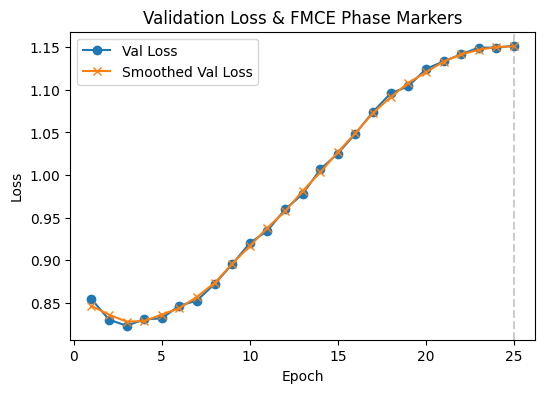

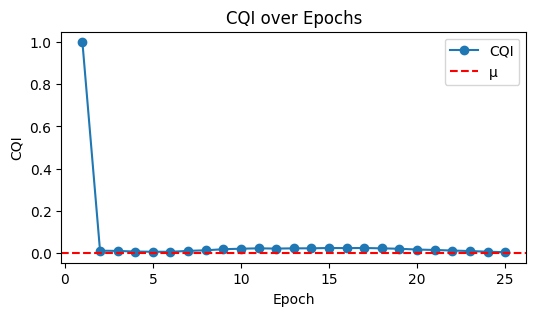

✅ Saved epoch markers to: /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_markers.json


In [8]:

#@title 📉 Compute CQI, convergence epoch & FMCE phase markers

import json, numpy as np, matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

logs_path = os.path.join(CFG.ckpt_root, "epoch_logs.json")
with open(logs_path, "r") as f:
    epoch_logs = json.load(f)

val_loss = np.array(epoch_logs["val_loss"], dtype=float)
epochs = np.arange(1, len(val_loss) + 1)

# 1) Smooth validation loss
window = min(CFG.cqi_window, len(val_loss))
smoothed = uniform_filter1d(val_loss, size=window)

def compute_cqi(series, B):
    if len(series) < 2:
        return 1.0
    diffs = np.abs(np.diff(series))
    B = min(B, len(diffs))
    if B <= 0:
        return float(diffs.mean()) if len(diffs) > 0 else 1.0
    return float(diffs[-B:].mean())

CQIs = []
for i in range(1, len(smoothed) + 1):
    CQIs.append(compute_cqi(smoothed[:i], CFG.cqi_window))
CQIs = np.array(CQIs)

print("Val loss   :", val_loss)
print("Smoothed   :", smoothed)
print("CQI series :", CQIs)

# 2) Find convergence epoch EK based on CQI threshold
mu = CFG.cqi_threshold
conv_epoch = len(smoothed)
for i, cqi in enumerate(CQIs, start=1):
    if cqi <= mu:
        conv_epoch = i
        break
print(f"CQI threshold μ = {mu:.1e}, convergence epoch EK = {conv_epoch}")

# 3) E0 = epoch with max smoothed loss
E0 = int(np.argmax(smoothed) + 1)
print("E0 (max-loss epoch) =", E0)

# 4) Divide [E0, EK] into K phases in log-loss space
K = min(CFG.K_phases, max(1, conv_epoch - E0 + 1))
log_loss = np.log(smoothed + 1e-8)
log_start = log_loss[E0 - 1]
log_end   = log_loss[conv_epoch - 1]
total_drop = log_start - log_end
per_segment = total_drop / K if K > 0 else 0.0

phase_edges = []
current_target = log_start - per_segment

for e in range(E0 + 1, conv_epoch + 1):
    if log_loss[e - 1] <= current_target or e == conv_epoch:
        phase_edges.append(e)
        current_target -= per_segment
        if len(phase_edges) >= K - 1:  # E0 is the first phase marker
            break

epoch_markers = [E0] + sorted(set(phase_edges))
epoch_markers = epoch_markers[:K]
while len(epoch_markers) < K:
    epoch_markers.append(conv_epoch)

epoch_markers = sorted(epoch_markers)
print("K =", K, "epoch markers:", epoch_markers)

# 5) Plot loss + markers
plt.figure(figsize=(6, 4))
plt.plot(epochs, val_loss, label="Val Loss", marker="o")
plt.plot(epochs, smoothed, label="Smoothed Val Loss", marker="x")
for b in epoch_markers:
    plt.axvline(b, color="gray", linestyle="--", alpha=0.4)
plt.title("Validation Loss & FMCE Phase Markers")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# CQI curve
plt.figure(figsize=(6, 3))
plt.plot(epochs, CQIs, marker="o", label="CQI")
plt.axhline(mu, color="red", linestyle="--", label="μ")
plt.title("CQI over Epochs")
plt.xlabel("Epoch")
plt.ylabel("CQI")
plt.legend()
plt.show()

markers_path = os.path.join(CFG.ckpt_root, "epoch_markers.json")
with open(markers_path, "w") as f:
    json.dump({"E0": E0, "EK": conv_epoch, "markers": epoch_markers}, f, indent=2)
print("✅ Saved epoch markers to:", markers_path)


In [19]:
# 🧬 Helper: extract pooled hidden states from a given epoch checkpoint

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification, DataCollatorWithPadding

def get_layer_hidden_states(
    ckpt_dir: str,
    layer_idx: int,
    dataset,
    tokenizer,
    batch_size: int,
    pooling: str,
    device: str,
):
    """
    Load a checkpoint, run the dataset once, and return pooled hidden states
    from the specified BERT layer.

    Args:
        ckpt_dir: directory of the saved BERT checkpoint.
        layer_idx: which layer index to use (-1 = last layer).
        dataset: tokenized dataset (with input_ids, attention_mask, labels/label).
        tokenizer: tokenizer for padding.
        batch_size: batch size for extraction.
        pooling: "mean" or "cls".
        device: "cuda" or "cpu".

    Returns:
        reps: np.ndarray of shape [N, hidden_size].
    """
    print(f"[get_layer_hidden_states] Loading model from {ckpt_dir}")
    model = BertForSequenceClassification.from_pretrained(ckpt_dir)
    model.to(device)
    model.eval()

    collator = DataCollatorWithPadding(tokenizer)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collator)

    all_reps = []

    with torch.no_grad():
        for batch in loader:

            # --- 兼容 label / labels ---
            if "labels" in batch:
                batch.pop("labels")
            elif "label" in batch:
                batch.pop("label")

            # move to device
            batch = {k: v.to(device) for k, v in batch.items()}

            # forward to get hidden states
            outputs = model.bert(
                **batch,
                output_hidden_states=True,
                return_dict=True,
            )
            hidden_states = outputs.hidden_states  # len = num_layers + 1

            # layer index处理（支持负索引）
            num_hidden_layers = len(hidden_states) - 1
            if layer_idx < 0:
                idx = num_hidden_layers + layer_idx
            else:
                idx = layer_idx

            if not (0 <= idx <= num_hidden_layers):
                raise ValueError(f"Invalid layer_idx={layer_idx}, num_hidden_layers={num_hidden_layers}")

            rep = hidden_states[idx]  # [B, seq_len, hidden]

            # pooling
            if pooling == "mean":
                mask = batch["attention_mask"].unsqueeze(-1)
                rep = (rep * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-8)
            elif pooling == "cls":
                rep = rep[:, 0, :]
            else:
                raise ValueError(f"Unknown pooling='{pooling}'.")

            all_reps.append(rep.cpu())

    reps = torch.cat(all_reps, dim=0)
    print(f"[get_layer_hidden_states] reps shape = {reps.shape}")
    return reps.numpy()


In [24]:
#@title 📦 Build FMCS dataset according to all epochs (with debug prints)

import os, glob, re
import numpy as np

# 🔍 先打印当前 ckpt_root
print("CFG.ckpt_root =", CFG.ckpt_root)

# 打印 ckpt_root 下面现在有哪些东西
if os.path.exists(CFG.ckpt_root):
    print("\nContents under ckpt_root:")
    for name in os.listdir(CFG.ckpt_root):
        print("  ", name)
else:
    print("⚠️ ckpt_root does NOT exist!")

# 自动找出所有 epoch_xx 目录，并按数字排序
pattern = os.path.join(CFG.ckpt_root, "epoch_*")
print("\nGlob pattern =", pattern)

epoch_dirs = sorted(glob.glob(pattern))
print("Matched epoch dirs:", epoch_dirs)

epoch_markers = []
for d in epoch_dirs:
    # 假设目录名是 epoch_1, epoch_2, ...
    base = os.path.basename(d)
    m = re.search(r"epoch_(\d+)$", base)
    if m:
        epoch_markers.append(int(m.group(1)))
    else:
        print("⚠️ Skip non-matching dir name:", base)

epoch_markers = sorted(epoch_markers)
K = len(epoch_markers)

print("\nUsing epoch markers (all epochs):", epoch_markers)
print("Number of phases (K) =", K)
print(f"Using {len(train_extract)} samples from training set for FMCS.")

if K == 0:
    raise RuntimeError("No epoch_* directories found under ckpt_root. "
                       "Check CFG.ckpt_root or whether checkpoints were saved.")

# ----------------- FMCS 构建部分 -----------------
features_list = []
labels_list   = []

subset_size = 2000   # 每个阶段抽样 2000 条

for phase_id, epoch_idx in enumerate(epoch_markers, start=1):
    ckpt_dir = os.path.join(CFG.ckpt_root, f"epoch_{epoch_idx}")
    print(f"\nPhase {phase_id}/{K} — extracting from epoch {epoch_idx} ({ckpt_dir})")

    # ---- 随机抽 2000 条样本 ----
    if len(train_extract) > subset_size:
        idx = np.random.choice(len(train_extract), subset_size, replace=False)
        dataset_subset = train_extract.select(idx)
    else:
        dataset_subset = train_extract

    # ---- Extract feature maps ----
    reps = get_layer_hidden_states(
        ckpt_dir=ckpt_dir,
        layer_idx=CFG.target_layer,
        dataset=dataset_subset,
        tokenizer=tokenizer,
        batch_size=CFG.eval_batch_size,
        pooling=CFG.feature_pooling,
        device=CFG.device,
    )

    features_list.append(reps)
    labels_list.append(np.full((reps.shape[0],), phase_id, dtype=np.int64))


CFG.ckpt_root = /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25

Contents under ckpt_root:
   epoch_1
   epoch_2
   epoch_3
   epoch_4
   epoch_5
   epoch_6
   epoch_7
   epoch_8
   epoch_9
   epoch_10
   epoch_11
   epoch_12
   epoch_13
   epoch_14
   epoch_15
   epoch_16
   epoch_17
   epoch_18
   epoch_19
   epoch_20
   epoch_21
   epoch_22
   epoch_23
   epoch_24
   epoch_25
   epoch_logs.json
   epoch_markers.json

Glob pattern = /content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_*
Matched epoch dirs: ['/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_1', '/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_10', '/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_11', '/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_12', '/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_13', '/content/drive/MyDrive/ExplainableNLP/BERT_yahoo_ckpts_25/epoch_14', '/content/drive/MyDrive/ExplainableNLP/BERT_y

In [26]:
X = np.concatenate(features_list, axis=0)
y = np.concatenate(labels_list, axis=0)

np.save(feature_path, X)
np.save(label_path, y)

In [30]:
#@title ✅ Quick sanity check of FMCS dataset

import numpy as np, os

feature_path = os.path.join(CFG.fmcs_dir, f"fmcs_features_layer{CFG.target_layer}.npy")
label_path   = os.path.join(CFG.fmcs_dir, f"fmcs_labels_layer{CFG.target_layer}.npy")

features = np.load(feature_path)
labels   = np.load(label_path)

print("=== FMCS dataset summary ===")
print("Features shape:", features.shape)
print("Labels shape  :", labels.shape)
print("Label range   :", labels.min(), "→", labels.max())
print("Unique labels :", np.unique(labels))

print("\nFeature statistics:")
print("  mean:", float(features.mean()))
print("  std :", float(features.std()))
print("  min :", float(features.min()))
print("  max :", float(features.max()))


=== FMCS dataset summary ===
Features shape: (50000, 256)
Labels shape  : (50000,)
Label range   : 1 → 25
Unique labels : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25]

Feature statistics:
  mean: -7.292743975995108e-05
  std : 0.6933752298355103
  min : -3.271488666534424
  max : 3.232748031616211


# stage2

In [1]:
# =========================
# Stage 2: Train MLP on FMCS
# =========================

import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ------------------------
# Config
# ------------------------
class CFG:
    fmcs_dir = "/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_25"  # 根据你实际的目录调整
    feature_file = "fmcs_features_layer-1.npy"  # 和 stage1 保存的一致
    label_file   = "fmcs_labels_layer-1.npy"

    val_ratio = 0.2          # 80% 训练，20% 验证
    batch_size = 512
    num_epochs = 30
    lr = 1e-3
    hidden_dims = [512, 256]  # MLP 隐藏层维度
    device = "cuda" if torch.cuda.is_available() else "cpu"
    seed = 42


# 固定随机种子（方便复现实验）
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG.seed)

# ------------------------
# 1. 读取 FMCS 数据
# ------------------------
feature_path = os.path.join(CFG.fmcs_dir, CFG.feature_file)
label_path   = os.path.join(CFG.fmcs_dir, CFG.label_file)

X = np.load(feature_path).astype(np.float32)  # [N, D]
y = np.load(label_path).astype(np.int64)      # [N]

print("Loaded features:", X.shape)
print("Loaded labels  :", y.shape, "min =", y.min(), "max =", y.max())
unique_labels = np.unique(y)
print("Unique labels  :", unique_labels)

# 注意：我们之前的标签是 1..K，这里转换成 0..K-1 方便 PyTorch CrossEntropyLoss
y = y - y.min()
num_classes = len(np.unique(y))
print("Remapped labels to 0..K-1, K =", num_classes)

# ------------------------
# 2. 划分 train / val
# ------------------------
N = X.shape[0]
indices = np.arange(N)
np.random.shuffle(indices)

split = int(N * (1.0 - CFG.val_ratio))
train_idx = indices[:split]
val_idx   = indices[split:]

X_train, y_train = X[train_idx], y[train_idx]
X_val,   y_val   = X[val_idx],   y[val_idx]

print("Train size:", X_train.shape[0])
print("Val size  :", X_val.shape[0])

# 对特征做简单标准化：以 train 为基准
mean = X_train.mean(axis=0, keepdims=True)
std  = X_train.std(axis=0, keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_val   = (X_val   - mean) / std

# ------------------------
# 3. 构建 Dataset & DataLoader
# ------------------------
class FMCSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = FMCSDataset(X_train, y_train)
val_dataset   = FMCSDataset(X_val,   y_val)

train_loader = DataLoader(train_dataset, batch_size=CFG.batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=CFG.batch_size, shuffle=False)

# ------------------------
# 4. 定义一个简单的 MLP
# ------------------------
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(0.2))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

input_dim = X.shape[1]
model = MLP(input_dim=input_dim,
            hidden_dims=CFG.hidden_dims,
            num_classes=num_classes).to(CFG.device)

print(model)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr)

# ------------------------
# 5. 训练 & 验证循环
# ------------------------
def run_epoch(loader, train: bool):
    if train:
        model.train()
    else:
        model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in loader:
        batch_x = batch_x.to(CFG.device)
        batch_y = batch_y.to(CFG.device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * batch_x.size(0)
        preds = logits.argmax(dim=-1)
        correct += (preds == batch_y).sum().item()
        total += batch_x.size(0)

    avg_loss = total_loss / max(total, 1)
    acc = correct / max(total, 1)
    return avg_loss, acc

best_val_acc = 0.0
best_state_dict = None

for epoch in range(1, CFG.num_epochs + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss,   val_acc   = run_epoch(val_loader,   train=False)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state_dict = model.state_dict()

    print(f"[Epoch {epoch:02d}] "
          f"Train loss={train_loss:.4f}, acc={train_acc:.4f} | "
          f"Val loss={val_loss:.4f}, acc={val_acc:.4f}")

print(f"\nBest val acc = {best_val_acc:.4f}")

# ------------------------
# 6. 可选：保存最优模型
# ------------------------
ckpt_path = os.path.join(CFG.fmcs_dir, "mlp_fmcs_best.pt")
if best_state_dict is not None:
    torch.save({
        "model_state_dict": best_state_dict,
        "input_dim": input_dim,
        "hidden_dims": CFG.hidden_dims,
        "num_classes": num_classes,
        "mean": mean,
        "std": std,
    }, ckpt_path)
    print("✅ Saved best MLP checkpoint to:", ckpt_path)
else:
    print("⚠ No best_state_dict recorded, not saving model.")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_25/fmcs_features_layer-1.npy'